# 🛡️ SpamShield — Probabilistic SMS Spam Detection
**BAMAT207 Probability and Statistics · Project Activity**
**Topic:** Probability and Random Variables
**Student:** Mohammad Asif Shaik (25BDS0107) · **Faculty:** Dhivyaa C R

Classify an SMS as **Spam (1)** or **Genuine / Ham (0)** using dataset probabilities, Bayes' theorem,
a Bernoulli random variable and a Multinomial Naive Bayes classifier.

Dataset: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) — 5,574 labelled SMS messages.

In [1]:
# !pip install ucimlrepo   # uncomment on Google Colab if needed
import os, io, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

plt.style.use('dark_background')
PINK, LIME, CYAN, VIOLET, AMBER = '#ff2e88', '#7CFF6B', '#00e5ff', '#a66bff', '#ffb020'
os.makedirs('figures', exist_ok=True)

## 1. Dataset Handling
Load messages and labels → check missing values → remove duplicates → encode **Spam = 1, Ham = 0**.

In [2]:
LOCAL = os.path.join('data', 'SMSSpamCollection')
if os.path.exists(LOCAL):
    df = pd.read_csv(LOCAL, sep='\t', names=['label', 'text'], quoting=3)
    print('Loaded local copy of the UCI dataset')
else:
    try:
        from ucimlrepo import fetch_ucirepo          # official UCI loader
        d = fetch_ucirepo(id=228).data.original
        df = d.rename(columns={d.columns[0]: 'text', d.columns[1]: 'label'})[['label', 'text']]
    except Exception:
        url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(req).read()))
        df = pd.read_csv(z.open('SMSSpamCollection'), sep='\t', names=['label', 'text'], quoting=3)
    print('Downloaded from UCI')

print('Raw shape:', df.shape)
print('\nMissing values per column:'); print(df.isnull().sum())
n_dup = df.duplicated(subset=['text']).sum()
df = df.dropna().drop_duplicates(subset=['text']).reset_index(drop=True)
print(f'\nDuplicate messages removed: {n_dup}')
print('Clean shape:', df.shape)

df['label_num'] = df['label'].map({'spam': 1, 'ham': 0})
df['length'] = df['text'].str.len()
df.head()

Loaded local copy of the UCI dataset
Raw shape: (5574, 2)

Missing values per column:
label    0
text     0
dtype: int64

Duplicate messages removed: 403
Clean shape: (5171, 2)


,label,text,label_num,length
0,ham,"Go until jurong point, crazy.. Available only ...",0,111
1,ham,Ok lar... Joking wif u oni...,0,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155
3,ham,U dun say so early hor... U c already then say...,0,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61


### Cleaned dataset summary

In [3]:
summary = pd.DataFrame({
    'Item': ['Raw messages', 'Missing values', 'Duplicates removed', 'Clean messages',
             'Spam messages', 'Ham messages', 'Avg length — spam (chars)', 'Avg length — ham (chars)'],
    'Value': [5574, 0, n_dup, len(df), (df.label_num == 1).sum(), (df.label_num == 0).sum(),
              round(df[df.label_num == 1].length.mean(), 1), round(df[df.label_num == 0].length.mean(), 1)]})
summary

,Item,Value
0,Raw messages,5574.0
1,Missing values,0.0
2,Duplicates removed,403.0
3,Clean messages,5171.0
4,Spam messages,653.0
5,Ham messages,4518.0
6,Avg length — spam (chars),137.7
7,Avg length — ham (chars),70.9


## 2. Dataset Analysis
$$P(Spam)=\frac{\#\,spam}{\#\,total}\qquad P(Ham)=\frac{\#\,ham}{\#\,total}$$

Total messages : 5171
Spam messages  : 653   P(Spam) = 653/5171 = 0.1263
Ham messages   : 4518   P(Ham)  = 4518/5171 = 0.8737
Check: P(Spam) + P(Ham) = 1.0000


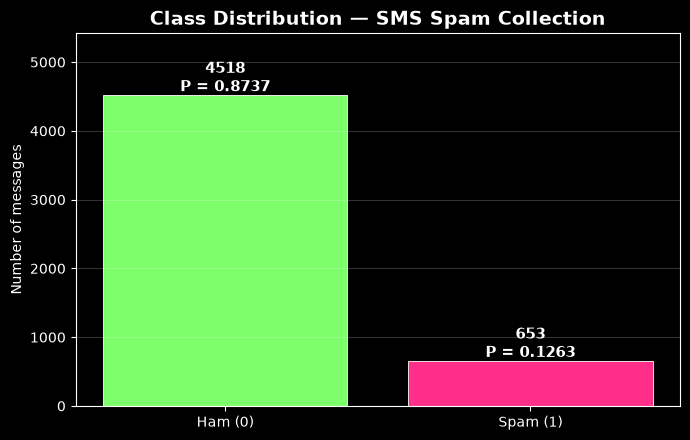

In [4]:
total = len(df)
n_spam = int((df.label_num == 1).sum())
n_ham = int((df.label_num == 0).sum())
p_spam, p_ham = n_spam / total, n_ham / total
print(f'Total messages : {total}')
print(f'Spam messages  : {n_spam}   P(Spam) = {n_spam}/{total} = {p_spam:.4f}')
print(f'Ham messages   : {n_ham}   P(Ham)  = {n_ham}/{total} = {p_ham:.4f}')
print(f'Check: P(Spam) + P(Ham) = {p_spam + p_ham:.4f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Ham (0)', 'Spam (1)'], [n_ham, n_spam], color=[LIME, PINK], edgecolor='white', linewidth=.6)
for b, n, p in zip(bars, [n_ham, n_spam], [p_ham, p_spam]):
    ax.text(b.get_x() + b.get_width()/2, n + 60, f'{n}\nP = {p:.4f}', ha='center', fontsize=11, fontweight='bold')
ax.set_title('Class Distribution — SMS Spam Collection', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of messages'); ax.set_ylim(0, n_ham * 1.2); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.savefig('figures/class_distribution.png', dpi=160); plt.show()

## 3. Word-Based Probability Analysis
For each suspicious word *w* ∈ {free, prize, win, urgent, offer}:

$$P(Spam\mid w)=\frac{\#\,spam\ containing\ w}{\#\,messages\ containing\ w}
\qquad\text{verified by Bayes:}\qquad P(Spam\mid w)=\frac{P(w\mid Spam)\,P(Spam)}{P(w)}$$

In [5]:
suspicious_words = ['free', 'prize', 'win', 'urgent', 'offer']

def contains_word(text, word):
    return bool(re.search(r'\b' + re.escape(word) + r'\b', text, re.IGNORECASE))

rows = []
for w in suspicious_words:
    has = df['text'].apply(lambda t: contains_word(t, w))
    n_w = int(has.sum()); n_sw = int((has & (df.label_num == 1)).sum())
    direct = n_sw / n_w
    p_w, p_w_spam = n_w / total, n_sw / n_spam
    bayes = p_w_spam * p_spam / p_w
    rows.append([w, n_w, n_sw, n_w - n_sw, p_w, p_w_spam, direct, bayes, direct / p_spam])
    print(f"'{w}':  P(Spam|{w}) = {n_sw}/{n_w} = {direct:.4f}   |   Bayes: "
          f"({p_w_spam:.4f} x {p_spam:.4f}) / {p_w:.4f} = {bayes:.4f}   {'MATCH' if np.isclose(direct, bayes) else 'DIFF'}")

words = pd.DataFrame(rows, columns=['word', 'msgs with word', 'spam', 'ham', 'P(word)', 'P(word|Spam)',
                                    'P(Spam|word) direct', 'P(Spam|word) Bayes', 'lift vs prior'])
words.round(4)

'free':  P(Spam|free) = 148/203 = 0.7291   |   Bayes: (0.2266 x 0.1263) / 0.0393 = 0.7291   MATCH
'prize':  P(Spam|prize) = 73/73 = 1.0000   |   Bayes: (0.1118 x 0.1263) / 0.0141 = 1.0000   MATCH
'win':  P(Spam|win) = 49/55 = 0.8909   |   Bayes: (0.0750 x 0.1263) / 0.0106 = 0.8909   MATCH
'urgent':  P(Spam|urgent) = 57/62 = 0.9194   |   Bayes: (0.0873 x 0.1263) / 0.0120 = 0.9194   MATCH
'offer':  P(Spam|offer) = 24/30 = 0.8000   |   Bayes: (0.0368 x 0.1263) / 0.0058 = 0.8000   MATCH


,word,msgs with word,spam,ham,P(word),P(word|Spam),P(Spam|word) direct,P(Spam|word) Bayes,lift vs prior
0,free,203,148,55,0.0393,0.2266,0.7291,0.7291,5.7733
1,prize,73,73,0,0.0141,0.1118,1.0000,1.0000,7.9188
2,win,55,49,6,0.0106,0.0750,0.8909,0.8909,7.0550
3,urgent,62,57,5,0.0120,0.0873,0.9194,0.9194,7.2802
4,offer,30,24,6,0.0058,0.0368,0.8000,0.8000,6.3351


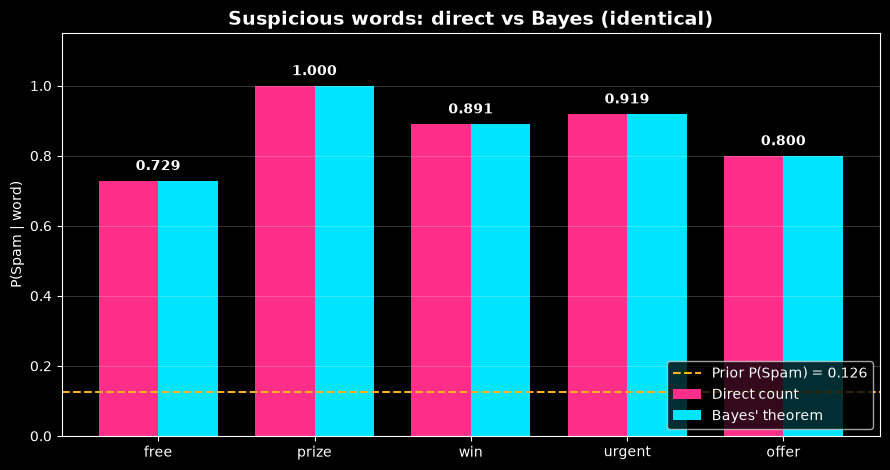

In [6]:
x = np.arange(len(words)); wd = .38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - wd/2, words['P(Spam|word) direct'], wd, color=PINK, label='Direct count')
ax.bar(x + wd/2, words['P(Spam|word) Bayes'], wd, color=CYAN, label="Bayes' theorem")
ax.axhline(p_spam, color=AMBER, ls='--', label=f'Prior P(Spam) = {p_spam:.3f}')
for i, v in enumerate(words['P(Spam|word) direct']):
    ax.text(i, v + .03, f'{v:.3f}', ha='center', fontweight='bold')
ax.set_xticks(x, words.word); ax.set_ylim(0, 1.15); ax.set_ylabel('P(Spam | word)')
ax.set_title('Suspicious words: direct vs Bayes (identical)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.savefig('figures/word_probabilities.png', dpi=160); plt.show()

## 4. Random Variable Analysis
$Y=1$ if spam, $Y=0$ if ham → $Y\sim\text{Bernoulli}(p)$ with $p=P(Spam)$.
$$E(Y)=0\cdot(1-p)+1\cdot p=p \qquad Var(Y)=E(Y^2)-[E(Y)]^2=p-p^2=p(1-p)$$

p = P(Spam)        = 0.1263
E(Y) = p           = 0.1263    (numpy mean of Y     = 0.1263)
Var(Y) = p(1 - p)  = 0.1103    (numpy variance of Y = 0.1103)
SD(Y)              = 0.3322


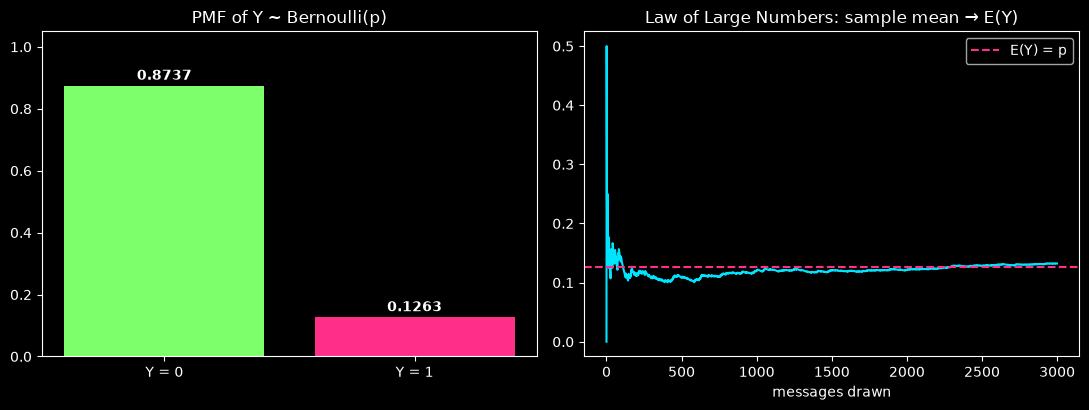

In [7]:
p = p_spam
E_Y, Var_Y = p, p * (1 - p)
y = df['label_num'].to_numpy()
print(f'p = P(Spam)        = {p:.4f}')
print(f'E(Y) = p           = {E_Y:.4f}    (numpy mean of Y     = {np.mean(y):.4f})')
print(f'Var(Y) = p(1 - p)  = {Var_Y:.4f}    (numpy variance of Y = {np.var(y):.4f})')
print(f'SD(Y)              = {np.sqrt(Var_Y):.4f}')

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].bar(['Y = 0', 'Y = 1'], [1 - p, p], color=[LIME, PINK])
for i, v in enumerate([1 - p, p]): axs[0].text(i, v + .02, f'{v:.4f}', ha='center', fontweight='bold')
axs[0].set_title('PMF of Y ~ Bernoulli(p)'); axs[0].set_ylim(0, 1.05)
rng = np.random.default_rng(7); draws = rng.choice(y, 3000)
axs[1].plot(np.cumsum(draws) / np.arange(1, 3001), color=CYAN)
axs[1].axhline(p, color=PINK, ls='--', label='E(Y) = p'); axs[1].legend()
axs[1].set_title('Law of Large Numbers: sample mean → E(Y)'); axs[1].set_xlabel('messages drawn')
plt.tight_layout(); plt.savefig('figures/random_variable.png', dpi=160); plt.show()

## 5. Data Preparation
80% train / 20% test with **stratified sampling**, then `CountVectorizer` turns text into word-count features.

In [8]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['text'], df['label_num'], test_size=0.2, random_state=42, stratify=df['label_num'])

vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train_raw)   # learn vocabulary on training data only
X_test = vectorizer.transform(X_test_raw)

print(f'Training messages: {X_train.shape[0]}  (spam ratio {y_train.mean():.4f})')
print(f'Testing messages : {X_test.shape[0]}  (spam ratio {y_test.mean():.4f})')
print(f'Vocabulary size  : {len(vectorizer.vocabulary_)} words')

Training messages: 4136  (spam ratio 0.1262)
Testing messages : 1035  (spam ratio 0.1266)
Vocabulary size  : 7669 words


## 6. Model Building — Multinomial Naive Bayes
$$P(Spam\mid m)\propto P(Spam)\prod_{w\in m}P(w\mid Spam)^{count(w)}$$
(with Laplace smoothing, α = 1). Suited to discrete word-count features.

Model trained. Learned class priors: [0.8738 0.1262]


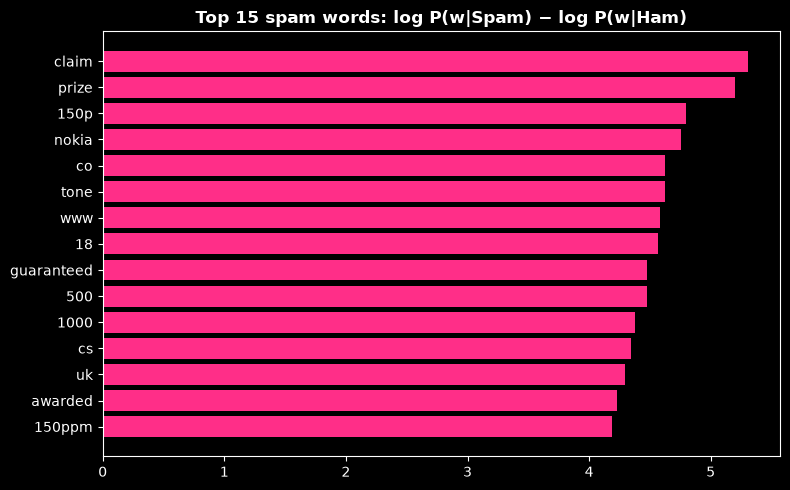

In [9]:
model = MultinomialNB()
model.fit(X_train, y_train)
print('Model trained. Learned class priors:', np.exp(model.class_log_prior_).round(4))

ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]
names = vectorizer.get_feature_names_out()
top = np.argsort(ratio)[::-1][:15]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(names[top][::-1], ratio[top][::-1], color=PINK)
ax.set_title('Top 15 spam words: log P(w|Spam) − log P(w|Ham)', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/top_spam_words.png', dpi=160); plt.show()

## 7. Model Evaluation
Accuracy, precision, recall, F1-score and the confusion matrix.

Accuracy : 0.9807
Precision: 0.9512
Recall   : 0.8931
F1-score : 0.9213

              precision    recall  f1-score   support

         Ham     0.9846    0.9934    0.9890       904
        Spam     0.9512    0.8931    0.9213       131

    accuracy                         0.9807      1035
   macro avg     0.9679    0.9432    0.9551      1035
weighted avg     0.9804    0.9807    0.9804      1035



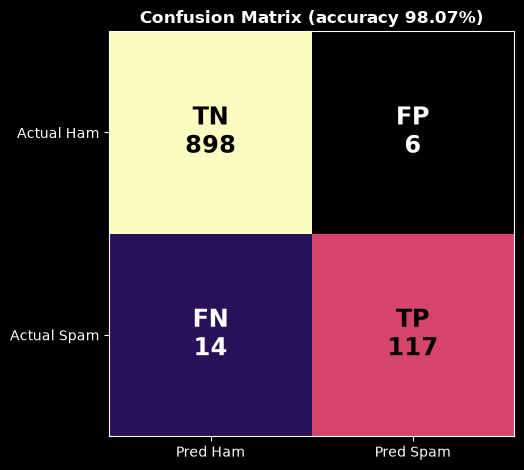

In [10]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f'Accuracy : {acc:.4f}')
print(f'Precision: {precision_score(y_test, y_pred):.4f}')
print(f'Recall   : {recall_score(y_test, y_pred):.4f}')
print(f'F1-score : {f1_score(y_test, y_pred):.4f}\n')
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam'], digits=4))

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(np.log1p(cm), cmap='magma')
lab = [['TN', 'FP'], ['FN', 'TP']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{lab[i][j]}\n{cm[i, j]}', ha='center', va='center', fontsize=17, fontweight='bold',
                color='black' if i == j else 'white')
ax.set_xticks([0, 1], ['Pred Ham', 'Pred Spam']); ax.set_yticks([0, 1], ['Actual Ham', 'Actual Spam'])
ax.set_title(f'Confusion Matrix (accuracy {acc:.2%})', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/confusion_matrix.png', dpi=160); plt.show()

### Errors the project asks us to identify

In [11]:
res = pd.DataFrame({'text': X_test_raw, 'actual': y_test, 'pred': y_pred,
                    'P(Spam|msg)': model.predict_proba(X_test)[:, 1].round(4)})
print(f'Spam messages incorrectly classified as genuine (False Negatives): {fn}')
print(f'Genuine messages incorrectly classified as spam (False Positives): {fp}')
pd.set_option('display.max_colwidth', 120)
res[(res.actual == 1) & (res.pred == 0)][['text', 'P(Spam|msg)']]

Spam messages incorrectly classified as genuine (False Negatives): 14
Genuine messages incorrectly classified as spam (False Positives): 6


,text,P(Spam|msg)
4499,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.3696
2642,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...,0.4532
3332,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",0.0049
1813,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,0.0000
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,0.0000
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,0.0000
3949,Missed call alert. These numbers called but left no message. 07008009200,0.0036
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",0.0000
772,Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile communit...,0.3744
5141,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,0.3508


In [12]:
res[(res.actual == 0) & (res.pred == 1)][['text', 'P(Spam|msg)']]

,text,P(Spam|msg)
4538,Nokia phone is lovly..,0.9468
4299,Have you laid your airtel line to rest?,0.8714
4416,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0.9161
3660,Unlimited texts. Limited minutes.,0.8643
2824,"Mostly sports type..lyk footbl,crckt..",0.5105
4321,"Received, understood n acted upon!",0.6021


## 8. Real-Time Testing

In [13]:
def predict_sms(message):
    proba = model.predict_proba(vectorizer.transform([message]))[0]
    print(f'Message : "{message}"')
    print(f'Prediction: {"Spam" if proba[1] >= 0.5 else "Ham"}')
    print(f'P(Spam | Message) = {proba[1]:.4f}')
    print(f'P(Ham | Message)  = {proba[0]:.4f}\n')

predict_sms('Congratulations! You have won a free prize. Claim now.')
predict_sms('URGENT! Your mobile number has won £2000. Call 09061701461 to claim')
predict_sms('Hey, are we still meeting at 4 for the project demo?')

Message : "Congratulations! You have won a free prize. Claim now."
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham | Message)  = 0.0000

Message : "URGENT! Your mobile number has won £2000. Call 09061701461 to claim"
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham | Message)  = 0.0000

Message : "Hey, are we still meeting at 4 for the project demo?"
Prediction: Ham
P(Spam | Message) = 0.0000
P(Ham | Message)  = 1.0000



In [14]:
# Type your own SMS (press Enter on an empty line to stop)
while True:
    try:
        msg = input('Enter an SMS: ')
    except Exception:          # no keyboard when the notebook is auto-run
        break
    if not msg.strip():
        break
    predict_sms(msg)

## Conclusion
* Spam is the minority class (P(Spam) ≈ 0.126); Y ~ Bernoulli(0.126) with Var(Y) ≈ 0.110.
* Words like **prize, urgent, win** raise the spam probability from 12.6% to 80–100% — computed directly
  and confirmed exactly with Bayes' theorem.
* Multinomial Naive Bayes reaches ≈ **98% accuracy** on unseen messages, with very few genuine messages blocked.
* Interactive version of this project: `streamlit run app.py`.